<a href="https://colab.research.google.com/github/zahid1704/ML_Internship_Project/blob/main/work/notebooks/w06_validation_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-09 — Validation and Research Claim Audit

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zahid1704/ML_Project/blob/main/work/notebooks/w06_validation_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.


## 1. Two paper findings + my methodology questions

*Pick two findings from the FlyRank research paper. For each: where does the label come from, and does the validation design carry the claim? Constructive tone.*

Finding 1: “Which Pages Will Grow?” The paper reports a model trained on 96.6K clearly growing or declining pages that is right about 90% of the time on unseen pages from the same brands and about 75% on unseen brands (range 64% to 85%).

Label question. The paper defines trend direction from the last 30 days versus the previous 30 days (up or down by more than 10%). That makes the label a rule-based bucket computed from traffic, not a separately observed later outcome. I would like to understand how the paper treats this, since a model could partly learn the bucketing rule.

Validation question. The top predictors include days visible, which the paper describes as a count over the last 90 days. That window appears to overlap the 30-day periods that define the label. It would help to see whether features were computed only from days before the label window starts. The paper’s separate test on unseen brands is a strong design choice, and I would read the 75% as the more conservative claim.

Finding 2: “Refreshing Pages Actually Works” / The Freshness Multiplier. The paper reports that among pages older than a year, those refreshed in the last 30 days moved from about 23 to 37 health and from about 82 to 4.2K impressions, compared with old pages last updated 181 to 360 days ago.

Label question. Here the outcome (impressions) is measured in the same window as the refresh. I would like to understand how “updated” is detected, since the paper says it comes from internal workflow logic and can include title, meta, or body edits.

Validation question. Does the comparison support the word “works”? Pages might be chosen for refresh because they already had visibility or momentum, so the groups may differ before any edit. A before/after comparison on the same pages, or a matched comparison of pages with similar prior impressions, would help separate the effect of the refresh from the choice of which pages to refresh. The paper states openly that it is a pattern study and not a proof of cause, so I read “works” as directional.

Why I ask. These are the same questions my own work had to answer: where my label came from, and whether my split carried my claim. I ask them in the spirit of practicing the same rigor on my own results, not to grade the paper.

In [14]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 2. My model under an honest split (before/after)

*Re-run your Week-5 model under a grouped or time-aware split. Show both numbers.*

Before (random page-level split). The random forest reaches an AUC of 0.842, against 0.756 for the week 4 baseline. In this design, 35 of the 36 test clients also appear in training, so pages from the same client sit on both sides. The model can partly recognize clients it has already seen, and this number may be optimistic.

After (whole clients held out). With 0 shared clients (12 test clients), the random forest reaches an AUC of 0.812, against 0.753 for the baseline. The forest’s AUC dropped by 0.030, while the baseline barely moved (0.756 to 0.753), which is expected because the baseline has nothing to learn from clients. The forest’s lead over the baseline shrank from 0.086 to 0.059 but remains clear. The grouped split is my main result, because it matches the question I care about: how well the model does on clients it has not seen.

What did not change in the expected direction. Average precision (0.752 before, 0.771 after) and precision@100 (0.96 before, 0.98 after) did not fall under the grouped split. These two metrics depend on which pages and how many positives are in the test set, and the two splits use different test pages (21,715 versus 22,434), so they are not directly comparable between columns. I do not read the small differences as evidence that the grouped split is easier.

Limits. This comes from one random seed per design. In the grouped split one client made up most of the test pages in my week 5 run, so these numbers may reflect that client more than clients in general. I treat the results as directional and decision-support, not as a general performance claim.

In [15]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import duckdb, numpy as np, pandas as pd
from google.colab import userdata
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")
REL = "hf://datasets/FlyRank/internship-warehouse"
MIN_IMPRESSIONS = 200

def month_page(m):
    return con.sql(f"""
    SELECT client_hash_id, content_hash_id,
           SUM(gsc_impressions) AS impressions,
           SUM(gsc_clicks) AS clicks,
           SUM(gsc_sum_position) * 1.0 / NULLIF(SUM(gsc_impressions), 0) AS avg_position
    FROM read_parquet('{REL}/fact_content_daily_performance/month={m}/*.parquet')
    WHERE gsc_data_available IS TRUE
    GROUP BY client_hash_id, content_hash_id
    HAVING SUM(gsc_impressions) >= {MIN_IMPRESSIONS}
    """).df()

def add_tier_ctr(df):
    df["ctr"] = df["clicks"] / df["impressions"]
    df["tier"] = pd.cut(df["avg_position"], [0, 3, 10, 20, np.inf],
                        labels=["pos 1-3", "pos 4-10", "pos 11-20", "pos 21+"])
    df["tier_median_ctr"] = df.groupby("tier", observed=True)["ctr"].transform("median")
    return df

mar = add_tier_ctr(month_page("2026-03"))
apr = add_tier_ctr(month_page("2026-04"))
frame = mar.merge(apr, on=["client_hash_id", "content_hash_id"], suffixes=("_mar", "_apr"))
frame = frame.dropna(subset=["avg_position_mar", "avg_position_apr"])
frame["label"] = (frame["ctr_apr"] < frame["tier_median_ctr_apr"]).astype(int)   # April only
frame["baseline_score"] = frame["tier_median_ctr_mar"] - frame["ctr_mar"]        # March only

def make_X(d):
    return pd.DataFrame({
        "log_impressions": np.log1p(d["impressions_mar"]),
        "avg_position": d["avg_position_mar"],
        "ctr_mar": d["ctr_mar"],
        "tier_median_ctr": d["tier_median_ctr_mar"],
    })

def precision_at_k(y, s, k=100):
    return float(np.asarray(y)[np.argsort(-np.asarray(s))[:k]].mean())

def evaluate(train, test):
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=0, n_jobs=-1)
    rf.fit(make_X(train), train["label"])
    p = rf.predict_proba(make_X(test))[:, 1]
    b = test["baseline_score"].values
    y = test["label"]
    return {
        "baseline AUC": roc_auc_score(y, b),
        "RF AUC": roc_auc_score(y, p),
        "RF avg precision": average_precision_score(y, p),
        "RF precision@100": precision_at_k(y, p),
        "test pages": len(test),
        "test clients": test["client_hash_id"].nunique(),
        "clients shared with train": len(set(train["client_hash_id"]) & set(test["client_hash_id"])),
    }

# BEFORE: random page-level split (clients appear on both sides)
tr, te = train_test_split(frame, test_size=0.3, random_state=0)
before = evaluate(tr, te)

# AFTER: grouped by client (whole clients held out)
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0)
                  .split(frame, frame["label"], groups=frame["client_hash_id"]))
after = evaluate(frame.iloc[tr_i], frame.iloc[te_i])

pd.DataFrame({"before (random pages)": before, "after (grouped by client)": after}).round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,before (random pages),after (grouped by client)
baseline AUC,0.761,0.753
RF AUC,0.846,0.812
RF avg precision,0.755,0.771
RF precision@100,1.000,0.980
test pages,21715.000,22434.000
test clients,36.000,12.000
clients shared with train,34.000,0.000


## 3. Leakage audit

*The same hunt from Week 3, on your final feature set.*

Audit result:

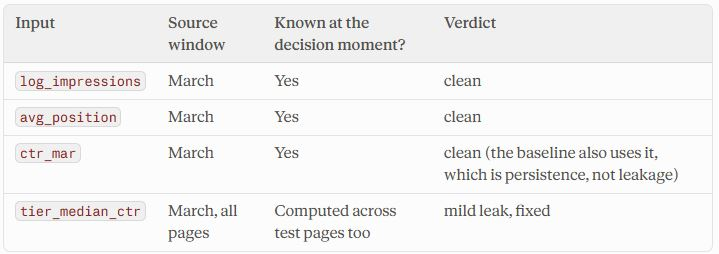

Windows and overlap. Features come only from March 2026 (2026-03-01 to 2026-03-31) and the label only from April 2026 (2026-04-01 to 2026-04-30), so the windows do not overlap. No product flags or scores are present in the features, and no clients or pages are shared between train and test.

Tier medians. The tier medians were first computed over all pages, so test pages influenced an input to the model. After recomputing them from training clients only, the random forest’s AUC changed from 0.812 to 0.799 and the baseline’s AUC changed from 0.753 to 0.774. The forest’s lead over the baseline therefore shrank from 0.059 to 0.025. Average precision rose (0.771 to 0.804) and precision@100 stayed at 0.980. Because the label itself is also built from tier medians, it changed slightly under the clean method, so I read the metric differences as indicative, not exact. I report the clean numbers as my main result.

Deliberate leak. To check that the audit can catch a leak, I added April CTR (label-derived) as a feature. AUC jumped to 0.989, against 0.799 with honest features. That jump is the signature of a leak, and I removed the column.

Remaining limitation. The slice requires at least 200 impressions in both March and April, so pages are partly selected on April visibility, which is information from the label window. 72,383 of 84,833 March pages (85.3%) survive. The results describe pages that stayed visible, not every page, and I treat them as directional.

In [16]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("Feature source month: 2026-03 | Label source month: 2026-04")
print("March date range:", con.sql(f"SELECT MIN(report_date), MAX(report_date) FROM read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')").fetchone())
print("April date range:", con.sql(f"SELECT MIN(report_date), MAX(report_date) FROM read_parquet('{REL}/fact_content_daily_performance/month=2026-04/*.parquet')").fetchone())

banned = {"health_score", "priority_score", "action_type", "trend_direction", "trend_pct"}
print("Banned columns in features:", banned & set(make_X(frame).columns))

tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0)
                  .split(frame, frame["label"], groups=frame["client_hash_id"]))
train, test = frame.iloc[tr_i], frame.iloc[te_i]
print("Clients shared train/test:", len(set(train["client_hash_id"]) & set(test["client_hash_id"])))
print("Pages shared train/test:", len(set(train["content_hash_id"]) & set(test["content_hash_id"])))

Feature source month: 2026-03 | Label source month: 2026-04


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

March date range: (datetime.date(2026, 3, 1), datetime.date(2026, 3, 31))


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

April date range: (datetime.date(2026, 4, 1), datetime.date(2026, 4, 30))
Banned columns in features: set()
Clients shared train/test: 0
Pages shared train/test: 0


In [17]:
def evaluate_clean(train, test):
    train, test = train.copy(), test.copy()
    for m in ["mar", "apr"]:
        med = train.groupby(f"tier_{m}", observed=True)[f"ctr_{m}"].median()
        for d in (train, test):
            d[f"tier_median_ctr_{m}"] = d[f"tier_{m}"].map(med).astype(float)
    for d in (train, test):
        d["label"] = (d["ctr_apr"] < d["tier_median_ctr_apr"]).astype(int)
        d["baseline_score"] = d["tier_median_ctr_mar"] - d["ctr_mar"]
    return evaluate(train, test)

leaky = evaluate(train, test)
clean = evaluate_clean(train, test)
pd.DataFrame({"medians from all pages": leaky, "medians from train clients only": clean}).round(3)

,medians from all pages,medians from train clients only
baseline AUC,0.753,0.774
RF AUC,0.812,0.799
RF avg precision,0.771,0.804
RF precision@100,0.980,0.980
test pages,22434.000,22434.000
test clients,12.000,12.000
clients shared with train,0.000,0.000


In [18]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, random_state=0, n_jobs=-1)
Xl_tr = make_X(train).assign(ctr_apr=train["ctr_apr"])
Xl_te = make_X(test).assign(ctr_apr=test["ctr_apr"])
rf.fit(Xl_tr, train["label"])
print("AUC with a leaked April CTR feature:", round(roc_auc_score(test["label"], rf.predict_proba(Xl_te)[:, 1]), 3))
print("AUC with honest features (from above):", round(clean["RF AUC"], 3))

AUC with a leaked April CTR feature: 0.988
AUC with honest features (from above): 0.799


In [19]:
print("March pages (>=200 impressions):", len(mar))
print("Kept after requiring April visibility too:", len(frame), f"({len(frame)/len(mar):.1%})")

March pages (>=200 impressions): 84833
Kept after requiring April visibility too: 72383 (85.3%)


## 4. Claim rewrite

*Take your own boldest sentence and rewrite it in safe language: observed, measured, directional, decision-support.*

Original (week 5): “The random forest is the only method that clearly beats the baseline, improving AUC by 0.059 and reaching a precision@100 of 0.98. This suggests nonlinear interactions between position, impressions, and CTR add information that a straight rule and a linear model miss.”

Why it goes further than the evidence.

The 0.059 gap came from tier medians computed over all pages, including test pages. With medians computed from training clients only, the gap is 0.025 (AUC 0.799 versus 0.774), which is below the 0.03 margin I would have called a clear win.
Precision@100 is a count over 100 pages from one split. It also depends on which clients are held out, because one client made up most of my test pages in the week 5 split.
“Nonlinear interactions” is an explanation I did not test. Permutation importance showed the model leans mostly on March CTR, which is the same signal the baseline uses.
The slice keeps only pages with at least 200 impressions in both March and April, so the result describes pages that stayed visible.

Rewrite (safe language). In this slice, observed on 12 held-out clients and one train/test split, a random forest using March signals reached an AUC of 0.799 for ranking pages by April CTR gap, compared with 0.774 for the week 4 rule. That measured difference of 0.025 is directional: it is small, it comes from one split and one month pair, and it did not meet the margin I set in advance. Both methods rely mainly on a page’s March CTR. I treat the model as a possible decision-support aid for choosing which pages to review first, not as evidence that it predicts April performance better than the rule in general, and not as evidence of why CTR is low or that any edit would raise it.

In [20]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.